## Dataset overview and artifact validation

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/products.parquet').exists(): ROOT = ROOT.parent
assert (ROOT / 'data/products.parquet').exists(), 'Start in the repository or evaluation directory.'
sys.path.insert(0, str(ROOT))
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, faiss
from types import SimpleNamespace
from unittest.mock import patch
from backend.search import ProductSearch
from backend.image_search import INDEX_DIR, CONFIG, digest
from backend.recommend import Recommender
products = pd.read_parquet(ROOT / 'data/products.parquet')
display(pd.DataFrame({'products': [len(products)], 'categories': [products.main_category.nunique()]}))

C:\Users\User\Projects\Relevia\.pixi\envs\default\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[transformers] `CLIPImageProcessor` requires torchvision (not installed); falling back to `CLIPImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `CLIPImageProcessorPil` directly to silence this warning.


,products,categories
0,1120,12


In [2]:
def no_rebuild(*args, **kwargs): raise RuntimeError('Text cache invalid; rebuilding disabled.')
with patch.object(ProductSearch, 'build_index', no_rebuild):
    text_search = ProductSearch()
manifest = json.loads((INDEX_DIR / 'manifest.json').read_text(encoding='utf-8'))
assert manifest['config'] == CONFIG
assert digest(INDEX_DIR / 'products.faiss') == manifest['index_sha256']
assert digest(INDEX_DIR / 'embeddings.npy') == manifest['vectors_sha256']
assert [e['id'] for e in manifest['entries']] == text_search.ids
assert all(e['path'] == p['image_path'] and digest(ROOT / e['path']) == e['sha256']
           for e, p in zip(manifest['entries'], text_search.products))
image_index = faiss.read_index(str(INDEX_DIR / 'products.faiss'))
assert image_index.ntotal == len(products) and image_index.d == CONFIG['dimension']
recommender = Recommender(text_search, SimpleNamespace(products=text_search.products, index=image_index))
print('Production recommender loaded; text and image indexes validated and reused.')

Production recommender loaded; text and image indexes validated and reused.


## Fresh recommendation ranking

In [3]:
results = []
for product_id in products.parent_asin:
    for item in recommender.recommend(product_id, limit=5):
        results.append({'seed': product_id, 'recommended': item['product_id'],
                        'category': item['category'], 'original_category': item['original_category']})
results = pd.DataFrame(results)
display(results.head())
print(f'{len(results)} fresh recommendation rows for {results.seed.nunique()} seeds')

,seed,recommended,category,original_category
0,B06XYHDX83,B00CCILYDA,TV & Video Players,DVD Players & Recorders
1,B06XYHDX83,B09RMRS767,TV & Video Players,DVD Players & Recorders
2,B06XYHDX83,B0BWSJV2XN,TV & Video Players,Streaming Media Players
3,B06XYHDX83,B0B5JSBZ1J,TV & Video Players,Blu-ray Players & Recorders
4,B06XYHDX83,B07K2TPCDR,TV & Video Players,Blu-ray Players & Recorders


5600 fresh recommendation rows for 1120 seeds


## Coverage, diversity and constraints

,Seeds with five,Catalog coverage,Mean source categories per list,Main-category compliance,Self recommendations
0,1.0,0.907,1.058,1.0,0


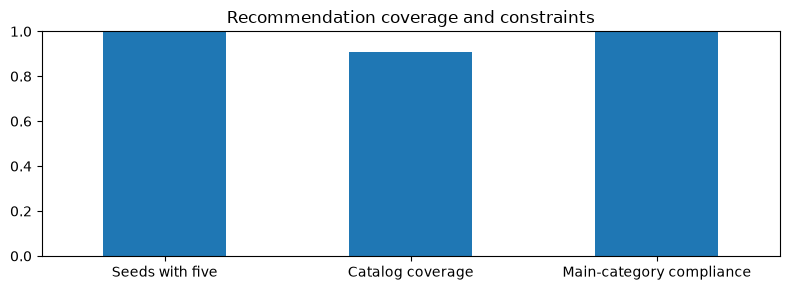

In [4]:
counts = results.groupby('seed').size().reindex(products.parent_asin, fill_value=0)
seed_category = products.set_index('parent_asin').main_category
coverage = results.recommended.nunique() / len(products)
diversity = results.groupby('seed').original_category.nunique().mean()
compliance = (results.category == results.seed.map(seed_category)).mean()
metrics = pd.DataFrame([{'Seeds with five': (counts==5).mean(), 'Catalog coverage': coverage,
                         'Mean source categories per list': diversity, 'Main-category compliance': compliance,
                         'Self recommendations': int((results.seed==results.recommended).sum())}])
display(metrics.round(3))
pd.Series({'Seeds with five': (counts==5).mean(), 'Catalog coverage': coverage,
           'Main-category compliance': compliance}).plot.bar(rot=0, ylim=(0,1), figsize=(8,3), title='Recommendation coverage and constraints')
plt.tight_layout(); plt.show()

## Interpretation

Coverage is the share of catalog items recommended at least once; source categories per list approximate diversity. Relevance ranking metrics require independent judgments.